-------------------------------------------------------
f(x) = x⁴ + 2x³ - 7x² + 3
-------------------------------------------------------
Two positive roots found: 
-------------------------------------------------------
Root 1: 1.6180  (full: 1.61803399)
Root 2: 0.7913  (full: 0.79128790)
-------------------------------------------------------
Convergence analysis (x0 = 1.4, x1 = 1.5):
-------------------------------------------------------
Approximate root : 1.6180  (full: 1.61803399)
Total iterations : 6
Error progression:
Iteration 1: e_1 = 0.2070 (2.0700e-01)
Iteration 2: e_2 = 0.1089 (1.0894e-01)
Iteration 3: e_3 = 0.0170 (1.6989e-02)
Iteration 4: e_4 = 0.0031 (3.0948e-03)
Iteration 5: e_5 = 0.0001 (1.1387e-04)
Iteration 6: e_6 = 0.0000 (6.2415e-07)
-------------------------------------------------------


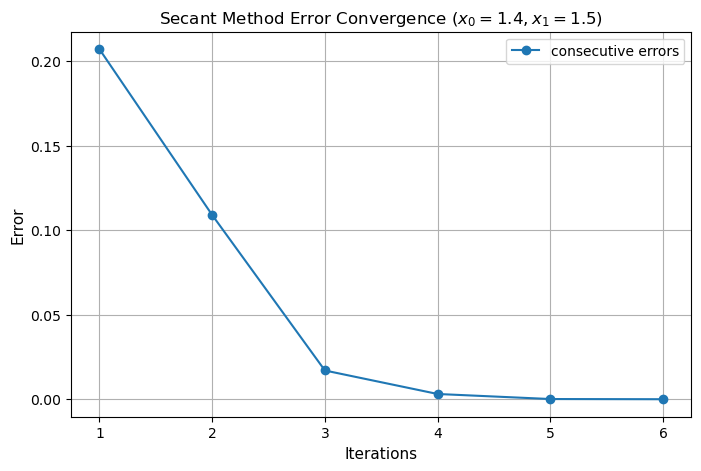

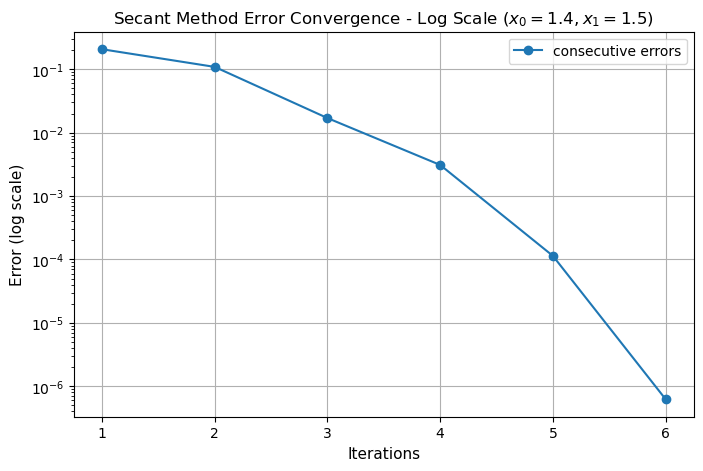

In [2]:
import numpy as np
import matplotlib.pyplot as plt

#declaration of function f(x)
def f(x):
    return x**4 + 2*x**3 - 7*x**2 + 3

#1. Secant method implementation
#Inputs: initial approximations (x0, x1), error tolerance (tol), maximum iterations (maxit)
#Outputs: approximate root (x_next), list of consecutive errors (errors)
def secant(x0, x1, tol, maxit):
    errors = []
    for i in range(maxit):
        denom = f(x1) - f(x0)
        if denom == 0:  #We avoid division by zero if f(x1) == f(x0) (ZeroDivisionError)
            break
        x_next = x1 - ((f(x1) * (x1 - x0)) / denom) #Iteration formula: x_{n+1} = x_n - f(x_n) * (x_n - x_{n-1}) / (f(x_n) - f(x_{n-1}))
        # Calculate and record consecutive error:
        err = np.abs(x_next - x1)
        errors.append(err)
        # Convergence stopping criterion
        if err < tol:
            break
        #We update points for the next iteration (we keep the two most recent approximations)    
        x0 = x1
        x1 = x_next
        
    return x_next, errors

# 2. Calculating the two distinct positive roots starting from x0 = i * 0.1, x1 = x0 + 0.1
x_i = [] #We keep a list to store the two distinct positive roots found
i = 0 #Step counter
tol = 1e-4 #Error tolerance

while True:
    x0 = i * 0.1
    x1 = x0 + 0.1
    #We avoid division by zero prior to the function call
    if f(x1) - f(x0) == 0:
        i += 1
        continue
        
    s_sol, s_err = secant(x0, x1, tol, 15)
    
    #We check if the method actually converged (last error < tol)
    if len(s_err) > 0 and s_err[-1] < tol:
        #We store the first valid root found
        if len(x_i) == 0:
            x_i.append(s_sol)
            i += 1
        #We check if the root differs from the first one in the first 3 decimal digits
        elif round(s_sol, 3) == round(x_i[0], 3):
            i += 1
            continue
        #Second distinct root found; loop termination
        else:
            x_i.append(s_sol)
            break
    else:
        #The method did not converge within maxit = 15; we move to the next interval
        i += 1

#Output printing rounded to 4 decimal digits
print("-" * 55)
print("f(x) = x⁴ + 2x³ - 7x² + 3")
print("-" * 55)
print("Two positive roots found: ")
print("-" * 55)
print(f"Root 1: {x_i[0]:.4f}  (full: {x_i[0]:.8f})")
print(f"Root 2: {x_i[1]:.4f}  (full: {x_i[1]:.8f})")
print("-" * 55)

#3. Convergence study and error plot for x0 = 1.4, x1 = 1.5
sol, errors = secant( 1.4, 1.5, 1e-4, 10)
print("Convergence analysis (x0 = 1.4, x1 = 1.5):")
print("-" * 55)
print(f"Approximate root : {sol:.4f}  (full: {sol:.8f})")
print(f"Total iterations : {len(errors)}")
print("Error progression:")
for index, error_value in enumerate(errors, start=1):
    print(f"Iteration {index}: e_{index} = {error_value:.4f} ({error_value:.4e})")
print("-" * 55)

#We generate the error convergence plot
plt.figure(figsize = (8, 5))
iterations = range(1, len(errors) + 1)
plt.plot(iterations, errors, marker='o', label='consecutive errors')
plt.xlabel('Iterations', fontsize=11)
plt.ylabel('Error', fontsize=11)
plt.title('Secant Method Error Convergence ($x_0 = 1.4, x_1 = 1.5$)', fontsize=12)
plt.xticks(iterations) #We display integer iteration ticks on the x-axis
plt.grid()
plt.legend()
plt.show()

#We generate the error convergence plot (Logarithmic Scale)
plt.figure(figsize = (8, 5))
iterations = range(1, len(errors) + 1)
plt.plot(iterations, errors, marker='o', label='consecutive errors')
plt.yscale('log')
plt.xlabel('Iterations', fontsize=11)
plt.ylabel('Error (log scale)', fontsize=11)
plt.title('Secant Method Error Convergence - Log Scale ($x_0 = 1.4, x_1 = 1.5$)', fontsize=12)
plt.xticks(iterations) #We display integer iteration ticks on the x-axis
plt.grid()
plt.legend()
plt.show()